# COVID-19 case fatality rate in Germany: daily vs cumulative CFR across two waves

**Question:** how lethal was COVID-19 in Germany during the first and second waves, measured by the case fatality rate (CFR)? How much does the answer depend on *how* the CFR is measured?

**Two measures**, both lag-adjusted. Deaths on day $t$ are matched with cases reported 15 days earlier, roughly the time from diagnosis to death:
- **Daily CFR:** new deaths on day $t$ ÷ new cases on day $t-15$. It reacts immediately, but it is noisy.
- **Cumulative CFR:** total deaths up to $t$ ÷ total cases up to $t-15$. It is smooth, but it trends and lags, and consecutive values are strongly dependent by construction.

**Data:** daily German cases and deaths from Our World in Data, for two periods:
- **Wave 1:** deaths from 11 Mar to 13 Jul 2020;
- **Wave 2:** deaths from 5 Nov 2020 to 4 Feb 2021.

**Contents:**
1. Data cleaning
2. Time series of both measures
3. Descriptive statistics and distribution checks
4. Confidence intervals for the mean, variance and standard deviation of the daily CFR
5. How dependent are consecutive days?
6. Daily vs cumulative CFR
7. Wave 1 vs wave 2
8. Conclusions

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

plt.rcParams["figure.figsize"] = (10, 3.5)
rng = np.random.default_rng(2021)

## 1. Data and cleaning

Three kinds of days are removed from the raw series:
- **The first 20 days of wave 1** (11–30 March 2020). Testing was still limited, and on some days one or two cases were matched with deaths, which gives a CFR of 100%. These values reflect under-detection, not lethality.
- **Negative daily deaths** (11 Apr and 6 Jul 2020). These are downward corrections of earlier reports.
- **Two extreme days**, which are data artefacts: 25 Jun 2020 (12 deaths on 16 cases = 75%) and 25 Jan 2021 (831 deaths on 948 cases = 88%).

In [2]:
raw = {w: pd.read_excel(f"data/wave{w}_raw.xlsx") for w in (1, 2)}
clean = {w: pd.read_excel(f"data/wave{w}_clean.xlsx") for w in (1, 2)}

for w in (1, 2):
    for df in (raw[w], clean[w]):
        df["daily_cfr"] = 100 * df["new_deaths"] / df["new_cases"]
        df["cumulative_cfr"] = 100 * df["total_deaths"] / df["total_cases"]
        df["date"] = pd.to_datetime(df["date_for_deaths"])
    removed = raw[w][~raw[w]["date"].isin(clean[w]["date"])]
    lag = (pd.to_datetime(clean[w]["date_for_deaths"]) - pd.to_datetime(clean[w]["date_for_cases"])).dt.days.unique()
    print(f"Wave {w}: {len(raw[w])} raw days -> {len(clean[w])} after cleaning "
          f"({len(removed)} removed), {clean[w]['date'].min():%d %b %Y} - {clean[w]['date'].max():%d %b %Y}, lag = {lag[0]} days")

print("\nRemoved days outside the start-up period:")
print(pd.concat([raw[w][~raw[w]["date"].isin(clean[w]["date"]) & (raw[w]["n"] > 20 if w == 1 else True)]
                 .assign(wave=w) for w in (1, 2)])[["wave", "date", "new_deaths", "new_cases", "daily_cfr"]]
      .round(2).to_string(index=False))

Wave 1: 125 raw days -> 102 after cleaning (23 removed), 31 Mar 2020 - 13 Jul 2020, lag = 15 days
Wave 2: 92 raw days -> 91 after cleaning (1 removed), 05 Nov 2020 - 04 Feb 2021, lag = 15 days

Removed days outside the start-up period:
 wave       date  new_deaths  new_cases  daily_cfr
    1 2020-04-11         -31       6933      -0.45
    1 2020-06-25          12         16      75.00
    1 2020-07-06          -1        602      -0.17
    2 2021-01-25         831        948      87.66


## 2. Time series of both measures

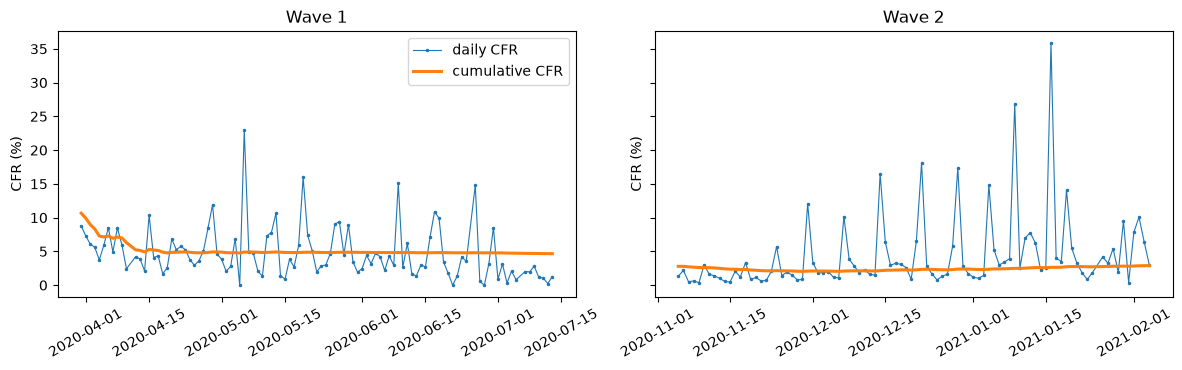

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, w in zip(axes, (1, 2)):
    d = clean[w]
    ax.plot(d["date"], d["daily_cfr"], ".-", lw=0.8, ms=3, label="daily CFR")
    ax.plot(d["date"], d["cumulative_cfr"], "-", lw=2.2, label="cumulative CFR")
    ax.set_title(f"Wave {w}"); ax.set_ylabel("CFR (%)"); ax.tick_params(axis="x", rotation=30)
axes[0].legend(); plt.tight_layout(); plt.show()

**Reading the plots:**
- **Wave 1:** the cumulative CFR falls from about 11% to about 5% within the first two weeks, then stays almost flat. The daily CFR fluctuates around 4–5%, with frequent spikes, and drifts down towards July.
- **Wave 2:** the cumulative CFR barely moves, rising slowly from 2.0% to 2.9%. The daily CFR shows **regular spikes about once a week**, which grow larger in December and January.
- **The cumulative CFR** is a slow-moving average of the whole past, so consecutive values are almost identical. This matters for the statistical tests below.

## 3. Descriptive statistics and distribution checks

In [4]:
def describe(x):
    x = pd.Series(x)
    return pd.Series({"n": len(x), "mean": x.mean(), "std": x.std(ddof=1), "min": x.min(), "Q1": x.quantile(.25),
                      "median": x.median(), "Q3": x.quantile(.75), "max": x.max(), "skewness": x.skew(),
                      "Shapiro-Wilk p": stats.shapiro(x).pvalue})

summary = pd.DataFrame({f"wave {w} {m}": describe(clean[w][f"{m}_cfr"]) for w in (1, 2) for m in ("daily", "cumulative")})
summary.round(3)

,wave 1 daily,wave 1 cumulative,wave 2 daily,wave 2 cumulative
n,102.000,102.000,91.000,91.000
mean,4.734,5.174,4.313,2.405
std,3.794,1.054,5.664,0.257
min,0.000,4.661,0.364,2.039
Q1,2.086,4.802,1.357,2.151
median,3.838,4.838,2.291,2.358
Q3,6.056,4.892,4.721,2.626
max,23.002,10.657,35.853,2.886
skewness,1.851,3.465,3.212,0.313
Shapiro-Wilk p,0.000,0.000,0.000,0.000


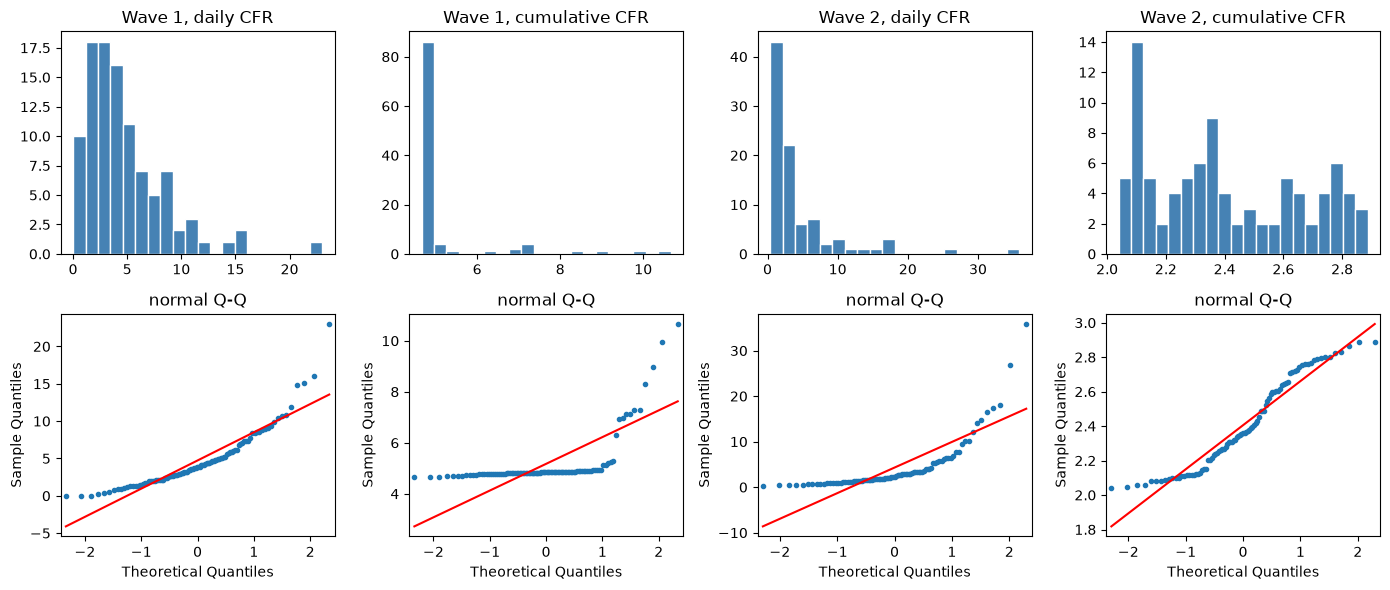

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for j, (w, m) in enumerate([(1, "daily"), (1, "cumulative"), (2, "daily"), (2, "cumulative")]):
    x = clean[w][f"{m}_cfr"]
    axes[0, j].hist(x, bins=20, color="steelblue", edgecolor="white"); axes[0, j].set_title(f"Wave {w}, {m} CFR")
    sm.qqplot(x, line="s", ax=axes[1, j], markersize=3); axes[1, j].set_title("normal Q-Q")
plt.tight_layout(); plt.show()

None of the four series is normal: every Shapiro–Wilk p-value is far below 0.05. The daily CFR is right-skewed, with a few days of very high lethality. The cumulative CFR is bounded and trending, so its "distribution" mostly reflects the time path.

This has two consequences:
- **Intervals for the mean** can still use the large-sample normal approximation (central limit theorem, n > 90), provided the days are close to independent; see section 5.
- **Intervals for the variance and standard deviation** based on the chi-square distribution *require* normal data. They are computed below as the textbook method, then checked against a bootstrap interval that does not need normality.

## 4. Confidence intervals for the daily CFR

In [6]:
def ci_mean_z(x, alpha):
    x = np.asarray(x); z = stats.norm.ppf(1 - alpha / 2); se = x.std(ddof=1) / np.sqrt(len(x))
    return x.mean() - z * se, x.mean() + z * se

def ci_var_chi2(x, alpha):
    x = np.asarray(x); n = len(x); s2 = x.var(ddof=1)
    return (n - 1) * s2 / stats.chi2.ppf(1 - alpha / 2, n - 1), (n - 1) * s2 / stats.chi2.ppf(alpha / 2, n - 1)

def ci_bootstrap(x, stat, alpha, B=10_000):
    x = np.asarray(x); boots = np.array([stat(rng.choice(x, len(x))) for _ in range(B)])
    return tuple(np.quantile(boots, [alpha / 2, 1 - alpha / 2]))

rows = []
for w in (1, 2):
    x = clean[w]["daily_cfr"]
    for alpha in (0.10, 0.05, 0.01):
        lo_v, hi_v = ci_var_chi2(x, alpha)
        rows.append({"wave": w, "confidence": f"{1 - alpha:.0%}",
                     "mean (z)": "[%.2f, %.2f]" % ci_mean_z(x, alpha),
                     "variance (chi²)": "[%.2f, %.2f]" % (lo_v, hi_v),
                     "std dev (chi²)": "[%.2f, %.2f]" % (np.sqrt(lo_v), np.sqrt(hi_v)),
                     "std dev (bootstrap)": "[%.2f, %.2f]" % ci_bootstrap(x, lambda v: v.std(ddof=1), alpha)})
pd.DataFrame(rows)

,wave,confidence,mean (z),variance (chi²),std dev (chi²),std dev (bootstrap)
0,1,90%,"[4.12, 5.35]","[11.59, 18.45]","[3.40, 4.30]","[2.97, 4.57]"
1,1,95%,"[4.00, 5.47]","[11.13, 19.37]","[3.34, 4.40]","[2.86, 4.74]"
2,1,99%,"[3.77, 5.70]","[10.29, 21.34]","[3.21, 4.62]","[2.64, 5.04]"
3,2,90%,"[3.34, 5.29]","[25.51, 41.76]","[5.05, 6.46]","[3.70, 7.37]"
4,2,95%,"[3.15, 5.48]","[24.44, 43.98]","[4.94, 6.63]","[3.42, 7.75]"
5,2,99%,"[2.78, 5.84]","[22.50, 48.77]","[4.74, 6.98]","[2.87, 8.32]"


The bootstrap interval for the standard deviation is noticeably **wider** than the chi-square one. The chi-square interval assumes normal data, and these right-skewed data have heavier tails. That makes the sample variance itself more variable than the normal theory predicts, so the chi-square interval is too optimistic here.

## 5. How dependent are consecutive days?

All the intervals above treat the days as an independent random sample. For a time series this has to be checked, using the autocorrelation function (ACF).

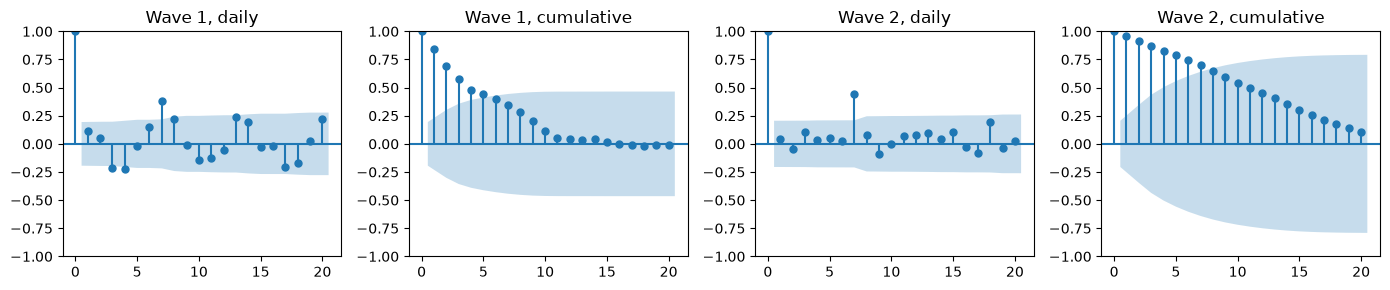

wave 1 daily     : lag-1 autocorrelation  0.11 -> effective n ≈  81.8 of 102
wave 1 cumulative: lag-1 autocorrelation  0.84 -> effective n ≈   8.7 of 102
wave 2 daily     : lag-1 autocorrelation  0.04 -> effective n ≈  83.3 of 91
wave 2 cumulative: lag-1 autocorrelation  0.96 -> effective n ≈   1.9 of 91


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
acf1 = {}
for ax, (w, m) in zip(axes, [(1, "daily"), (1, "cumulative"), (2, "daily"), (2, "cumulative")]):
    x = clean[w][f"{m}_cfr"]
    sm.graphics.tsa.plot_acf(x, lags=20, ax=ax, title=f"Wave {w}, {m}")
    acf1[(w, m)] = sm.tsa.acf(x, nlags=1)[1]
plt.tight_layout(); plt.show()

for (w, m), r in acf1.items():
    n = len(clean[w])
    n_eff = n * (1 - r) / (1 + r)          # effective sample size under an AR(1) approximation
    print(f"wave {w} {m:10s}: lag-1 autocorrelation {r:5.2f} -> effective n ≈ {n_eff:5.1f} of {n}")

**Cumulative CFR.** Autocorrelation is close to 1 and decays slowly. In wave 2, about 90 days carry the information of only two independent observations. Any interval that treats them as independent is far too narrow.

**Daily CFR.** There is little dependence between consecutive days, but a clear **7-day cycle**: the autocorrelation at lag 7 is about 0.4 in both waves. This is a reporting artefact:
- fewer cases are reported at weekends and on holidays;
- 15 days later, the CFR divides that day's deaths by those few cases and spikes;
- the largest wave 2 spike, in mid-January, matches cases from the New Year holiday.

The z-intervals for the daily CFR are therefore roughly right in width. Their *mean*, though, is pulled up by artificial spikes; see sections 6 and 7.

## 6. Daily vs cumulative CFR

Does the choice of measure change the estimated lethality? Two intervals for the mean difference (daily − cumulative) are shown:
- **Two-sample z-interval:** treats the two series as independent samples.
- **Paired interval on the daily differences:** more appropriate, because both measures are computed from the *same* days.

In [8]:
def ci_diff_independent(x, y, alpha):
    z = stats.norm.ppf(1 - alpha / 2); se = np.sqrt(x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y))
    return x.mean() - y.mean() - z * se, x.mean() - y.mean() + z * se

rows = []
for w in (1, 2):
    d, c = clean[w]["daily_cfr"], clean[w]["cumulative_cfr"]
    for alpha in (0.10, 0.05, 0.01):
        rows.append({"wave": w, "confidence": f"{1 - alpha:.0%}", "mean difference": d.mean() - c.mean(),
                     "independent z-interval": "[%.2f, %.2f]" % ci_diff_independent(d, c, alpha),
                     "paired interval": "[%.2f, %.2f]" % ci_mean_z(d - c, alpha)})
pd.DataFrame(rows).round(3)

,wave,confidence,mean difference,independent z-interval,paired interval
0,1,90%,-0.440,"[-1.08, 0.20]","[-1.05, 0.17]"
1,1,95%,-0.440,"[-1.20, 0.32]","[-1.17, 0.29]"
2,1,99%,-0.440,"[-1.44, 0.56]","[-1.40, 0.52]"
3,2,90%,1.908,"[0.93, 2.89]","[0.94, 2.88]"
4,2,95%,1.908,"[0.74, 3.07]","[0.75, 3.07]"
5,2,99%,1.908,"[0.38, 3.44]","[0.39, 3.43]"


- **Wave 1:** the daily CFR is on average slightly *lower* than the cumulative CFR. Every interval contains zero, so there is no significant difference at the 10%, 5% or 1% level.
- **Wave 2:** the mean daily CFR is about 1.9 percentage points *higher*, and every interval excludes zero.

The wave 2 gap is mostly about **how the averages are formed**, not about lethality:
- the cumulative CFR is a ratio of sums, so every *case* counts equally;
- the mean of the daily CFRs gives every *day* equal weight, including low-reporting days with a tiny denominator.

The median daily CFR in wave 2 (2.29%) is almost identical to the median cumulative CFR (2.36%). The weekly spikes create the difference in means.

## 7. Wave 1 vs wave 2

The daily CFR is the better measure for comparing the waves, because it does not carry history from before each period. A Welch two-sample comparison (unequal variances) and a Mann–Whitney test (no normality assumption) are both reported.

In [9]:
x1, x2 = clean[1]["daily_cfr"], clean[2]["daily_cfr"]
welch = stats.ttest_ind(x1, x2, equal_var=False)
mw = stats.mannwhitneyu(x1, x2)
print(f"mean daily CFR: wave 1 {x1.mean():.2f}%, wave 2 {x2.mean():.2f}% (difference {x1.mean() - x2.mean():+.2f} pp)")
print(f"medians:        wave 1 {x1.median():.2f}%, wave 2 {x2.median():.2f}%")
for alpha in (0.10, 0.05, 0.01):
    lo, hi = ci_diff_independent(x1, x2, alpha)
    print(f"{1 - alpha:.0%} CI for wave 1 - wave 2: [{lo:.2f}, {hi:.2f}]")
print(f"Welch t-test p = {welch.pvalue:.3f} | Mann-Whitney p = {mw.pvalue:.3f}")

pooled = {w: 100 * clean[w]["new_deaths"].sum() / clean[w]["new_cases"].sum() for w in (1, 2)}
print(f"case-weighted CFR over the period: wave 1 {pooled[1]:.2f}%, wave 2 {pooled[2]:.2f}%")

mean daily CFR: wave 1 4.73%, wave 2 4.31% (difference +0.42 pp)
medians:        wave 1 3.84%, wave 2 2.29%
90% CI for wave 1 - wave 2: [-0.74, 1.58]
95% CI for wave 1 - wave 2: [-0.96, 1.80]
99% CI for wave 1 - wave 2: [-1.39, 2.23]
Welch t-test p = 0.550 | Mann-Whitney p = 0.005
case-weighted CFR over the period: wave 1 4.66%, wave 2 2.85%


The comparison of means and the comparison of typical days disagree:
- **Means:** the mean daily CFRs are close (4.7% vs 4.3%), and the Welch test finds no difference (p ≈ 0.55).
- **Typical days:** the median falls from 3.8% to 2.3%, and the rank-based Mann–Whitney test finds a clear shift (p ≈ 0.005).
- **Case-weighted:** total deaths ÷ total lag-matched cases over each period gives 4.7% in wave 1 and 2.9% in wave 2.

The mean of the daily CFRs is inflated in wave 2 by the weekly reporting spikes, which mask the drop in lethality. The likely drivers are much wider testing, which finds milder cases, and better treatment. The rank test and the case-weighted CFR are the more reliable comparisons here.

## 8. Conclusions

- **Lethality fell between the waves.** The typical (median) daily CFR dropped from 3.8% to 2.3% (Mann–Whitney p ≈ 0.005), and the case-weighted CFR fell from 4.7% to 2.9%. A plain comparison of mean daily CFRs misses this (p ≈ 0.55), because reporting spikes inflate the wave 2 mean.
- **The daily CFR carries a weekly reporting cycle.** Weekend and holiday case reporting creates spikes 15 days later. A 7-day rolling or case-weighted CFR removes most of this artefact.
- **The cumulative CFR** is smooth but nearly perfectly autocorrelated, and dominated by the start of each period. It describes the period as a whole, but it is unsuitable for interval estimation that assumes independent observations.
- **Measurement choice changes the answer.** In wave 2 the mean daily CFR exceeds the cumulative CFR by about 1.9 pp, purely because of how days are weighted.
- **Statistical caveats.**
  - The daily CFR is strongly right-skewed. Chi-square intervals for its variance are too narrow, and the bootstrap gives a more honest range.
  - A fixed 15-day lag between case and death is a simplification.
  - Testing intensity changed between the waves, which moves the denominator.